# Estimating spatial metabolomics from spatial transcriptomics using Compass

## Brief introduction

In this tutorial, we demonstrate how to estimate spatial metabolomics maps from spatial transcriptomics datasets using Compass [[Wagner et.al, 2021](https://www.sciencedirect.com/science/article/pii/S0092867421007005)]. These inferred metabolite fluxes can then be integrated into MetaChat to infer metabolic cell communication (MCC).

Compass is a flux-balance-analysis (FBA)–based computational framework designed to infer cellular metabolic states from single-cell RNA sequencing data. It translates gene-expression levels of metabolic-enzyme-coding genes into reaction penalty scores, builds a constraint-based model of the metabolic network, and solves a set of linear programs to compute a score for every reaction in each cell.

The Compass algorithm is capable of estimating the abundance of around 429 different metabolites, offering a broader metabolite coverage compared to many alternative tools. However, this richer output comes at the cost of longer computational runtimes, so users should plan accordingly.

## Installation

You can follow the guideline of installation from [tutorials of Compass](https://compass-wagnerlab.readthedocs.io/en/latest/installation.html).

Create an independent environment
```bash
mamba create -n compass python=3.10
mamba activate compass
```

Install requirements:
```bash
python -m pip install numpy
python -m pip install git+https://github.com/wagnerlab-berkeley/Compass.git --upgrade
```

You can test if compass is sucessfully installed:
```bash
compass -h
```

The Compass framework uses the Gurobi Optimizer (a high-performance linear/linear-programming solver) to compute penalized reaction-scores by solving constrained optimization problems for each cell. To support academic research, Gurobi offers free full-featured academic licenses for faculty, students, and researchers at degree-granting institutions—these can be requested via their [official academic program webpage](https://www.gurobi.com/academia/academic-program-and-licenses/).

If you sucessfully get the license, you can download the `gurobi.lic` file from the [web license manager](https://license.gurobi.com/manager/licenses). Next, you will activate compass through:
```bash
compass --set-license <PATH_TO_LICENSE>
```

## Usage

We use the Visium HD dataset of  [mouse small intestine](https://www.10xgenomics.com/datasets/visium-hd-cytassist-gene-expression-libraries-of-mouse-intestine), which also can be download from [zenodo](https://zenodo.org/records/12629999).

In [1]:
# Importing packages
import os
import scanpy as sc
import anndata as ad
import metachat as mc

In [2]:
# This notebook expects to run from the folder that contains the `datasets/`
# directory downloaded from Zenodo. If you started Jupyter somewhere else,
# point it here first, for example:
#     os.chdir("/path/to/the/folder/that/contains/datasets")


Import raw datasets of spatial transcritomics.

In [3]:
adata_RNA = sc.read('datasets/mouse_small_intestine/adata_16um_subset_rna_raw.h5ad')

The data should be normalized and log-transformed (log1p) before running Compass.

In [4]:
adata_RNA.var_names_make_unique()
adata_RNA.raw = adata_RNA
sc.pp.normalize_total(adata_RNA, inplace=True, target_sum=1e5)
sc.pp.log1p(adata_RNA)

In [5]:
adata_RNA

AnnData object with n_obs × n_vars = 8531 × 19059
    obs: 'in_tissue', 'array_row', 'array_col', 'location_id', 'region', 'Cluster'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'Cluster_colors', 'spatial', 'spatialdata_attrs', 'log1p'
    obsm: 'spatial'

In [6]:
adata_RNA.write('datasets/mouse_small_intestine/adata_16um_subset_rna_normalized.h5ad')

Then, you can run compass on that normalized datasets in the `compass` environment.
```bash
compass --data <path to adata_16um_subset_rna_normalized.h5ad> \ 
        --num-processes 128 \ 
        --species mus_musculus \  # if human, homo_sapines
        --model RECON2_mat \
        --output-dir <path to output folder> \
        --temp-dir <path to output folder> \
        --calc-metabolites \  # Please select open because we need the abundance of metabolites.
```

The output folder contains `reactions.tsv`, `secretions.tsv` and `uptake.tsv`.
MetaChat works from **`reactions.tsv`**, the matrix of reaction penalty scores
(reactions x cells) that Compass produces.

`mc.pp.generate_adata_met_compass` turns those reaction scores into a
metabolite-by-cell matrix in three steps:

1. **Per-reaction normalization across cells** (`norm`). A penalty score is only
   meaningful relative to the other cells, so each reaction is first put on a
   common scale. `norm="rank"` (the default) replaces each value by its
   percentile rank, which is robust to the heavy tails of the penalty
   distribution. `norm="minmax"` rescales each reaction linearly to [0, 1],
   which keeps the relative spacing between cells but is more sensitive to
   outliers.
2. **Stoichiometric aggregation to metabolites** (`score`). For each cytoplasmic
   metabolite, MetaChat collects every internal reaction that produces or
   consumes it, using the stoichiometry of the Recon2 model. `score="Prod"`
   keeps only the producing reactions, `score="Cons"` only the consuming ones,
   and `score="Balance"` (the default) takes production minus consumption, i.e.
   the net tendency of the cell to accumulate that metabolite.
3. **Pooling across reactions** (`agg`). Most metabolites participate in many
   reactions. `agg="topk_mean"` (the default) averages the `topk` strongest
   reactions per cell, so that one dominant route does not hide the others;
   `agg="max"` keeps only the single strongest reaction.

Only metabolites in the cytoplasmic `[c]` compartment are kept, and they are
mapped to HMDB IDs so that they can be matched against MetaChatDB.


In [7]:
adata_META = mc.pp.generate_adata_met_compass(
    compass_output="datasets/mouse_small_intestine/compass/reactions.tsv",
    score="Balance",
    norm="rank",
)

:::{note}
`norm` rescales every reaction **within one dataset**, so two datasets
normalized separately are not on a common scale. When you want to compare
conditions, pass all the Compass outputs together to
`mc.pp.generate_adata_met_compass_condition`, which normalizes them jointly:

> adata_A, adata_B = mc.pp.generate_adata_met_compass_condition(
>     compass_outputs=["condition_A/reactions.tsv", "condition_B/reactions.tsv"],
>     score="Balance",
>     norm="minmax",
> )

It returns one AnnData per entry of `compass_outputs`, in the same order, and
takes the same `score`, `norm`, `agg` and `topk` arguments. Cell barcodes that
repeat across conditions are handled internally.
:::

In [8]:
adata_META

AnnData object with n_obs × n_vars = 8531 × 1084

Then, we combine the spatial transcriptomics and metabolomics data.

In [9]:
adata_combined = ad.concat([adata_RNA, adata_META], axis=1, join="outer")
adata_combined.obs = adata_RNA.obs.copy()
adata_combined.uns = adata_RNA.uns.copy()
adata_combined.obsm = adata_RNA.obsm.copy()

In [10]:
adata_combined

AnnData object with n_obs × n_vars = 8531 × 20143
    obs: 'in_tissue', 'array_row', 'array_col', 'location_id', 'region', 'Cluster'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'Cluster_colors', 'spatial', 'spatialdata_attrs', 'log1p'
    obsm: 'spatial'

At this stage, we can visualize cytidine and lactate as examples, using their corresponding HMDB IDs.

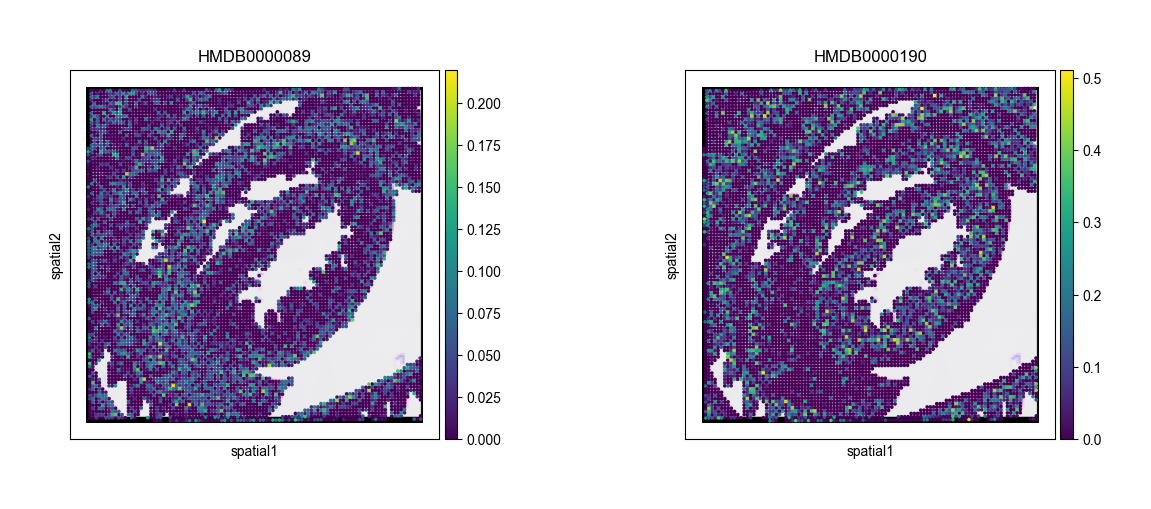

In [11]:
sc.pl.spatial(adata_combined, color=["HMDB0000089","HMDB0000190"])